# Team members:
  * ### Abdallah Said,
  * ### Miłosz Stec,
  * ### Maciek Kołakowski.

# <font color="red"> **1. Task Definition** </font>

*What is the engineering problem, and what constitutes a successful
solution? Define the objective, inputs and outputs, relevant constraints and
assumptions, and the criteria used to evaluate the solution*

---

## Theme:
Evolutionary Optimization in Engineering Design - application of evolutionary
algorithms to complex, multi-objective engineering problems with simulation-based or
experimental evaluation.

---

## Topic:
### <font color="green"> **Multi-objective PID tuning for a drone** </font>

---

## Goal:
The goal is to propse ,implement and tune a genetic algorithm which will tune the PID for different conditions

---

### Data:
Data will be obtain from Weebot simulation and/or from [Keggle dataset](https://www.kaggle.com/datasets/ziya07/quadcopter-pid-tuning-dataset/data)

---

### Main experiment and comparision:
Testing drone in different conditions in simulated enviroment

---

## Order of work:
1. Configure the enviroment
2. Process the dataset (necessary exploration, cleaning, preprocessing, splitting)
3. Analyze the dataset
4. importing the dataset into enviroment
5. build a represantaion for the data suitable for the algorithm!
6. objective function
7. cofiguration of an algorithm
8. fine-tune the model
9. Validate the model
10. Test the model
11. prepare report

---

## Team work plan:

### 1 lab:
1. Configure the enviroment  (Abdallah)
2. Process the dataset (necessary exploration, cleaning, preprocessing, splitting) (Maciek)
3. Analyze the dataset (Miłosz)
4. importing the dataset into enviroment (Abdallah)

### 2 lab:  
5. Build a represantaion for the data suitable for the algorithm (Miłosz)
6. Objective function (Abdallah)
7. Cofiguration of an algorithm (Maciek)

### 3 lab:  
8. Fine-tune the model (Maciek)
9. Validate the model (Abdallah)
10. Test the model (Miłosz)
11. Prepare report  (All)

---

# <font color="red"> **2. Data / system representation and preparation** </font>

*Where does the data come from:
measurements, simulations, synthetic generation, or a combination of these? Examine its relevant properties and potential quality issues, such as noise, missing values, outliers, imbalance, or limited coverage. Describe the required preprocessing and, where applicable, the division into training, validation, and test sets.*

---

This dataset contains simulated flight performance data for quadcopters, designed to optimize the Proportional-Integral-Derivative (PID) parameters for improved flight stability, responsiveness, and energy efficiency under dynamic conditions.

The dataset can be used for testing and optimizing multi-objective optimization algorithms for quadcopter flight control, specifically focusing on the balance between stability, response time, and energy consumption.

---

## Our simulated dataset has 15 features divided into 3 main areas od interest with columns named:
### Key Features:
* P_gain (float64)
* I_gain (float64)
* D_gain (float64)
### Flight Conditions:
* initial_pitch (float64)
* initial_roll (float64)
* initial_yaw (float64)
* wind_speed (float64)
* payload_weight (float64)
### Performance Metrics:
* rise_time (float64)
* settling_time (float64)
* overshoot_percent (float64)
* steady_state_error (float64)
* total_energy_consumed (float64)
* control_effort (float64)
* stability_score (float64)

---

Generally speaking this data appears to be good quality. There are no missing values, no outliers and it is balanced (probably due to being simulated)

The most correlation is between rise time and settling time

Positivly correlated:

    rise_time with settling_time
    wind_speed with steady_state_error
    payload_weight with control_effort

Negativly correlated:

    P_gain with rise_time, settling_time, control_effort
    initial_pitch with steady_state_error, overshoot_percent
    initial_yaw with control effort

Also there is a lot of corrrelation betweet stability score and wind speed , steady state error, overshoot percent, however this is to be expected as this value is calculated based on this 3.

    "stability_score: A measure of the system's stability based on overshoot, error, and wind speed."

---

# <font color="red"> **3. Input representation / features** </font>

*What information is provided to the model or solution method, and why? Describe any feature extraction, engineering, or selection required. Consider whether the selected representation omits relevant information or introduces unnecessary redundancy.*

---

## Data representation:

1. (Optimization) Used for Optimization:

| Variable Name | Type | Unit |
|---|---|---|
| `P_gain` | `float64` | Controller-dependent |
| `I_gain` | `float64` | Controller-dependent |
| `D_gain` | `float64` | Controller-dependent |

    PID = [P_gain, I_gain, D_gain]

2. (Flight condition) Used to Condition PID:

| Variable Name | Type | Unit |
|---|---|---|
| `initial_pitch` | `float64` | Degrees (°) |
| `initial_roll` | `float64` | Degrees (°) |
| `initial_yaw` | `float64` | Degrees (°)|
| `wind_speed` | `float64` | Metres per second (m/s) |
| `payload_weight` | `float64` | Grams (g) |

    C = [initial_pitch, initial_roll, initial_yaw, wind_speed, payload_weight]

3. (Observed performance) Used to Check Algorithm:

| Variable Name | Type | Unit |
|---|---|---|
| `rise_time` | `float64` | Seconds (s) |
| `settling_time` | `float64` | Seconds (s) |
| `overshoot_percent` | `float64` | Percent (%) |
| `steady_state_error` | `float64` | Depends on controlled output |
| `total_energy_consumed` | `float64` | Joules (J) |
| `control_effort` | `float64` | Depends on control-input units |
| `stability_score` | `float64` | Score (0–100) |
| `is_flipped` | `bool` | Boolean (`true` / `false`) |


    Q = (0,4 * rise_time) + (0,6 * settling_time) + (1 * overshoot_percent) + (0,1 * steady_state_error) + (0,1 * total_energy_consumed) + (0,5 * control_effort) + (0.8 * (1/stability_score))


---

# <font color="red"> **4. Model(s) / solution method** </font>

*Which model, algorithm, or solution method is used, and why is it suitable for the problem? Describe its structure, key parameters, and the training, fitting, identification, or optimization procedure. Where applicable, define a simple baseline or reference approach for comparison.*

Evolutionary algorithm.

We take x amount of all data 40% best and 60% random. Than we do a crossover between half of x. Than repeat and chceck for cost function.


Key Parameters:
* Population Size
* Elite Size
* Tournament Size
* Mutation Probability
* Mutation Strength

Baseline Comparison Approach

For evaluation, our evolutionary model's optimized PID values will be benchmarked against:

1. The default initial configurations from the dataset.
2. A simple heuristic-based PID tuning baseline.

# <font color="red"> **5. Experimental setup and comparative variants** </font>

*What exactly is being investigated or compared? Define compared variants, the factors varied between experiments, and the conditions kept fixed to ensure a fair comparison. Specify the evaluation metrics before analyzing the results and use repeated runs where randomness may affect the outcome.*

We compare objective cost function Q for a given PID configuration.

The dron model does not change at all.

For fair comparison the initial conditions are kept the same. For different conditions (for example different wind_speed or payload_weight) those initial conditions will change.

# <font color="red"> **6. Results, validation and interpretation** </font>

*Present and visualize the main results, with emphasis on validation using unseen data or operating conditions where applicable. Examine both successful and unsuccessful cases, identify relevant failure modes, and interpret the results in engineering terms rather than reporting numerical differences alone.*

# <font color="red"> **7. Conclusions, limitations and recommendations** </font>

*Provide a clear answer to the original task or research question. State which solution is recommended and under what conditions, discuss its main limitations and trade-offs, and indicate possible directions for further improvement or investigation.*




# <font color="red"> **8. AI Usage** </font>
AI was used to prepare code and to improve readibility of the raport.







In [ ]:
#biblioteki
try:
    import kagglehub
except ImportError:  # lokalnie (Webots) niepotrzebne
    kagglehub = None
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # lokalnie: drone_pid_dataset.csv obok notebooka

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


The most correlation is between rise time and settling time  

Positivly correlated:
* rise_time with settling_time
* wind_speed with steady_state_error
* payload_weight with control_effort

Negativly correlated:
* P_gain with rise_time, settling_time, control_effort
* initial_pitch with steady_state_error, overshoot_percent
* initial_yaw with control effort

Also there is a lot of corrrelation betweet stability score and wind speed , steady state error, overshoot percent, however this is to be expected as this value is calculated based on this 3.

> "stability_score: A measure of the system's stability based on overshoot, error, and wind speed."



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
First 5 rows:


,episode,scenario,flight_duration,p_gain,I_gain,D_gain,inital_pitch,initail_roll,initail_yaw,wind_speed,...,rise_time,settling_time,overshoot_percent,steady_state_error,Total_energy_consumed,stability_score,flipped,avg_position_x,avg_position_y,avg_position_z
0,1,1,9.424,2.5389,0.0033,0.7209,0.0,0.0,0.0,0.0,...,4.784,4.992,16.58,0.7698,2483.9713,0.5628,0,-8.6171,3.6632,0.7302
1,2,1,11.800,1.4044,0.0072,0.7723,0.0,0.0,0.0,0.0,...,5.304,0.000,1.66,0.7776,3130.4962,0.6233,0,-9.5286,3.7774,0.7224
2,3,1,10.144,2.0453,0.0062,0.9588,0.0,0.0,0.0,0.0,...,4.512,4.832,10.93,0.6964,2663.0821,0.6295,0,-9.0169,3.8240,0.8036
3,4,1,12.008,1.2015,0.0091,1.0258,0.0,0.0,0.0,0.0,...,6.040,0.000,0.00,0.7999,3329.9745,0.6162,0,-8.8016,4.1585,0.7001
4,5,1,11.416,1.4018,0.0017,0.6279,0.0,0.0,0.0,0.0,...,4.160,4.672,7.61,0.5684,3007.2310,0.6959,0,-8.4831,4.2677,0.9316



Dataset shape: (100, 21)

Columns:
['episode', 'scenario', 'flight_duration', 'p_gain', 'I_gain', 'D_gain', 'inital_pitch', 'initail_roll', 'initail_yaw', 'wind_speed', 'payload_weight', 'rise_time', 'settling_time', 'overshoot_percent', 'steady_state_error', 'Total_energy_consumed', 'stability_score', 'flipped', 'avg_position_x', 'avg_position_y', 'avg_position_z']

Data types:
episode                    int64
scenario                   int64
flight_duration          float64
p_gain                   float64
I_gain                   float64
D_gain                   float64
inital_pitch             float64
initail_roll             float64
initail_yaw              float64
wind_speed               float64
payload_weight           float64
rise_time                float64
settling_time            float64
overshoot_percent        float64
steady_state_error       float64
Total_energy_consumed    float64
stability_score          float64
flipped                    int64
avg_position_x         

,count,mean,std,min,25%,50%,75%,max
episode,100.0,50.500000,29.011492,1.0000,25.750000,50.50000,75.250000,100.0000
scenario,100.0,1.000000,0.000000,1.0000,1.000000,1.00000,1.000000,1.0000
flight_duration,100.0,8.310240,4.127753,0.0080,9.190000,9.67600,10.828000,12.0080
P_gain,100.0,1.978716,0.480094,1.2015,1.528975,1.98530,2.418700,2.7642
I_gain,100.0,0.005801,0.002607,0.0011,0.003550,0.00610,0.008025,0.0100
D_gain,100.0,0.843470,0.218026,0.5043,0.641100,0.82740,1.033700,1.1835
initial_pitch,100.0,0.000000,0.000000,0.0000,0.000000,0.00000,0.000000,0.0000
initial_roll,100.0,0.000000,0.000000,0.0000,0.000000,0.00000,0.000000,0.0000
initial_y,100.0,0.000000,0.000000,0.0000,0.000000,0.00000,0.000000,0.0000
wind_speed,100.0,0.000000,0.000000,0.0000,0.000000,0.00000,0.000000,0.0000



Unique values per column:
episode                  100
scenario                   1
flight_duration           78
P_gain                   100
I_gain                    62
D_gain                    99
initial_pitch              1
initial_roll               1
initial_y                  1
wind_speed                 1
payload_weight             1
rise_time                 64
settling_time             34
overshoot_percent         71
steady_state_error        96
total_energy_consumed     95
stability_score           91
flipped                    2
avg_position_x            99
avg_position_y            99
avg_position_z            96
dtype: int64
Missing values per column:
episode                  0
scenario                 0
flight_duration          0
P_gain                   0
I_gain                   0
D_gain                   0
initial_pitch            0
initial_roll             0
initial_y                0
wind_speed               0
payload_weight           0
rise_time                0


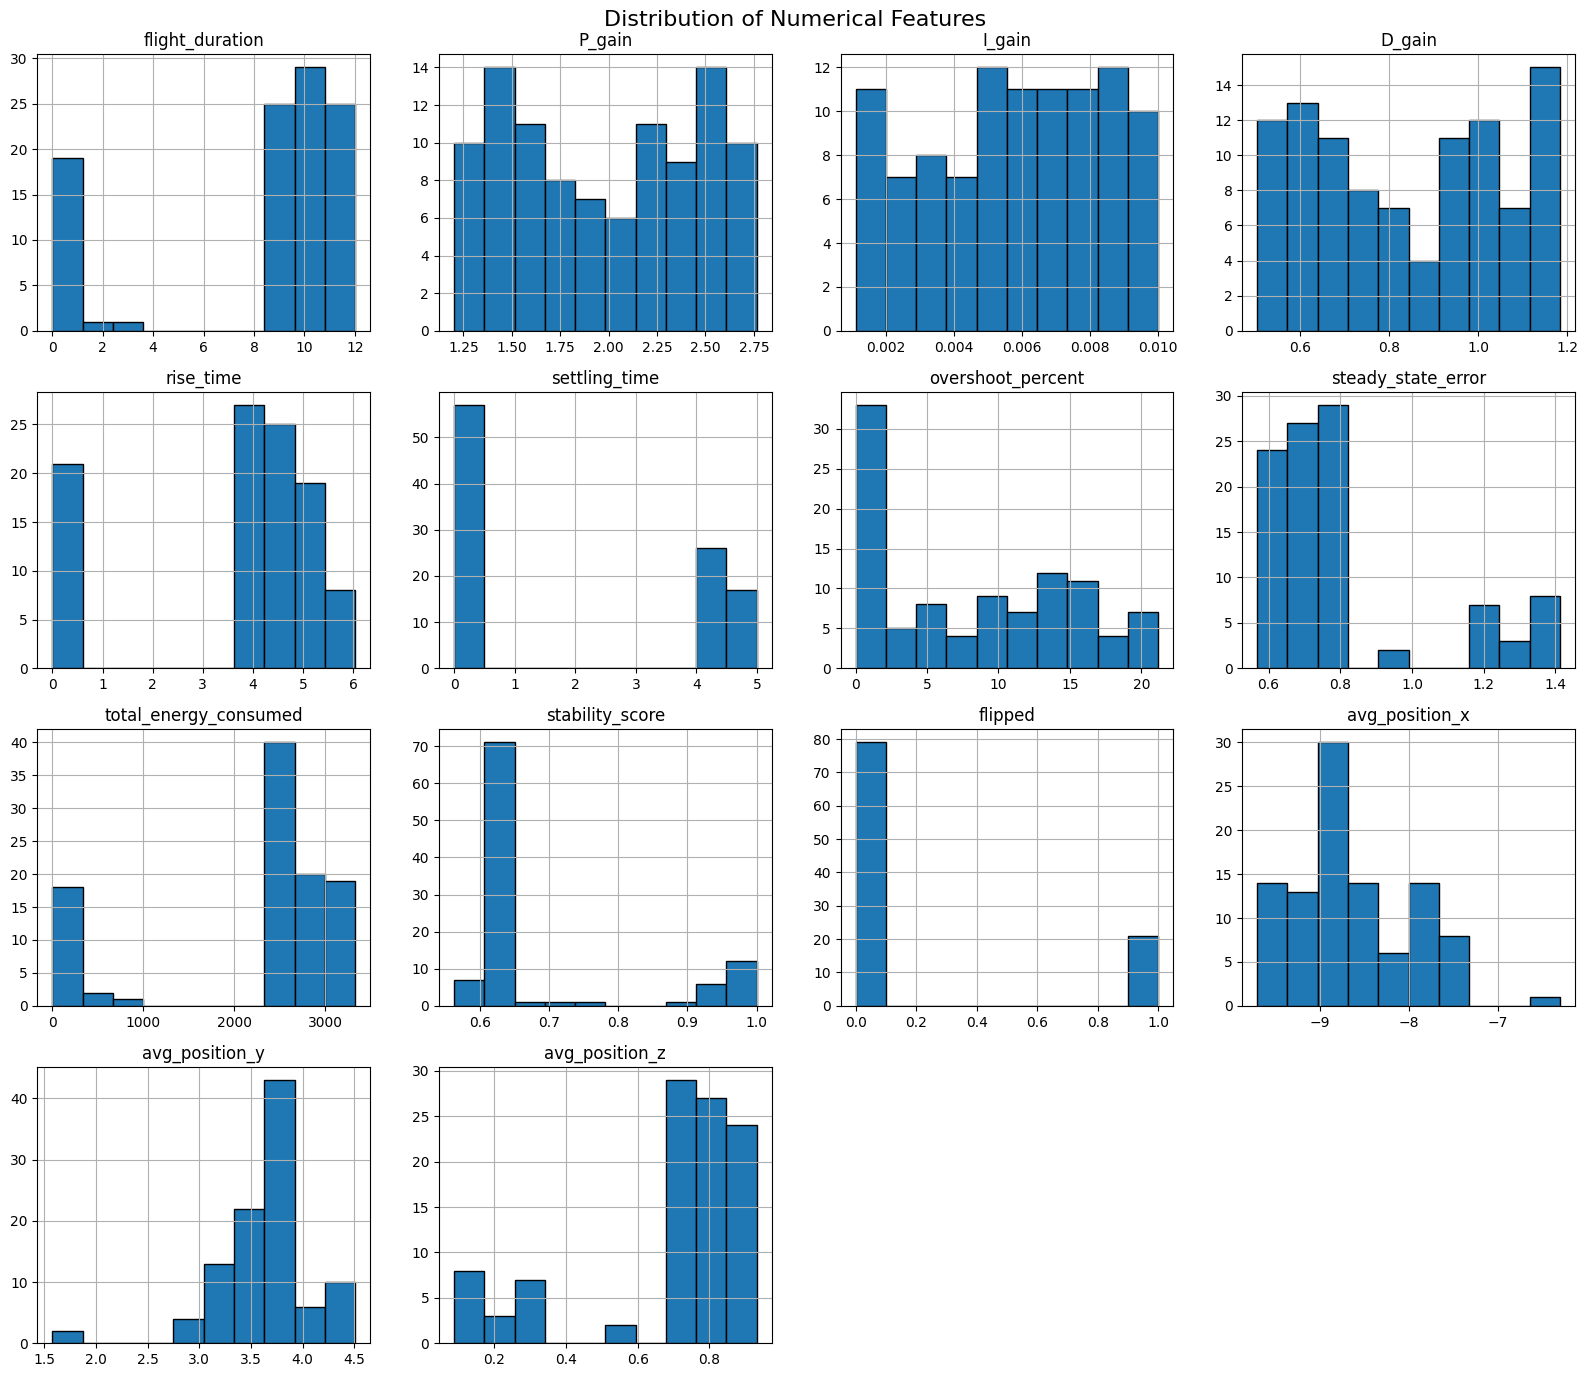

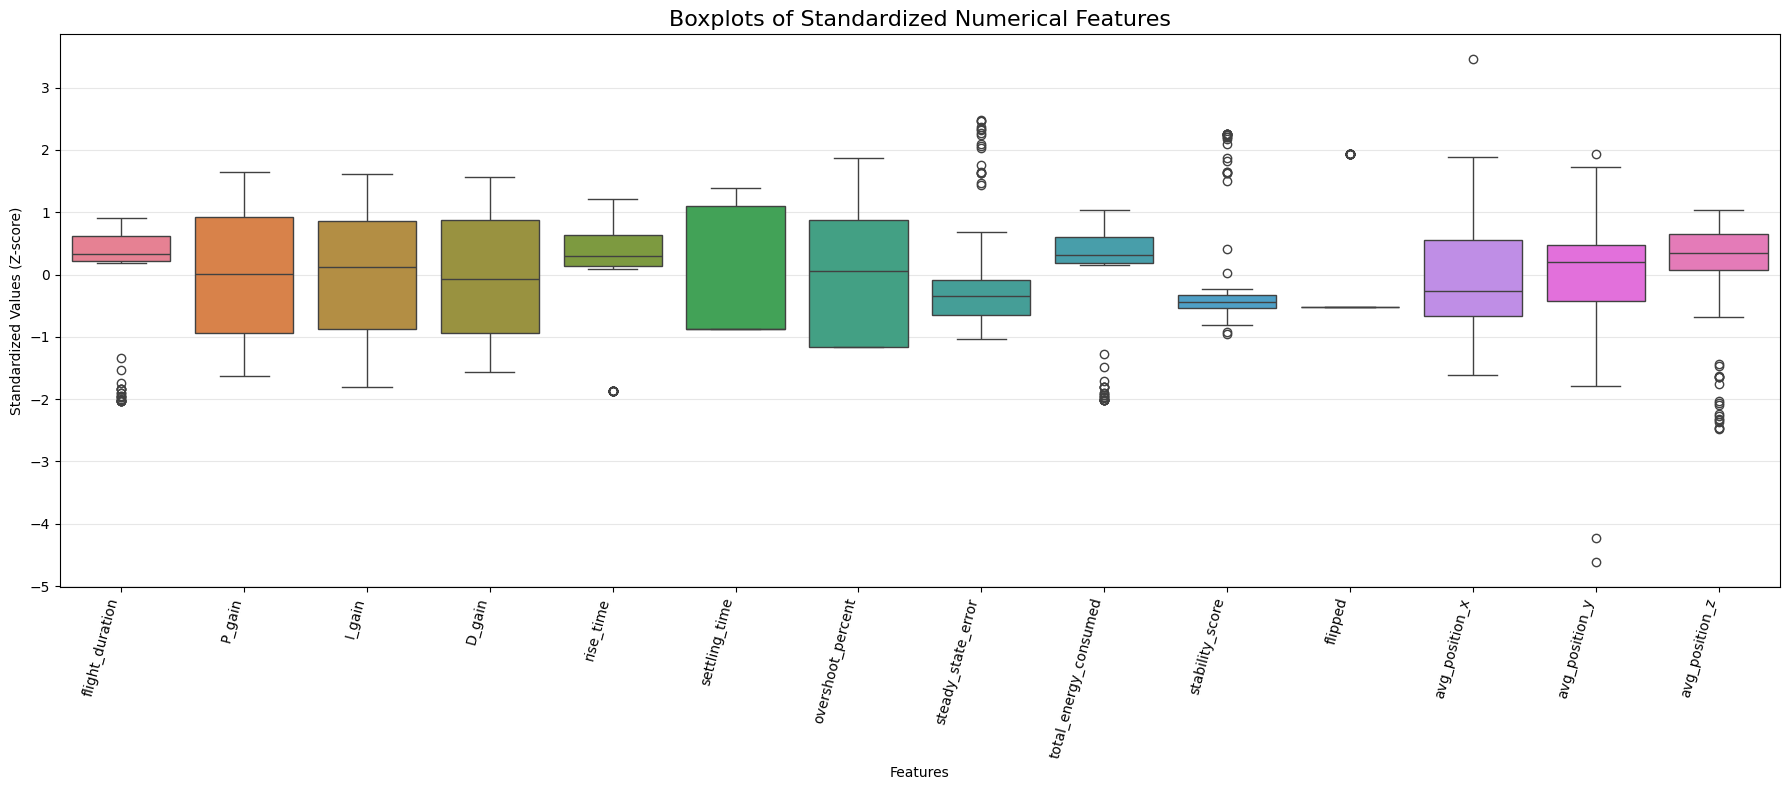

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler

# Google Drive (Colab) albo plik lokalny (uruchomienie z Webots)
try:
    from google.colab import drive

    drive.mount('/content/drive')

    file_path = Path(
        "/content/drive/MyDrive/drone_pid_dataset.csv"
    )
except ImportError:
    file_path = Path("drone_pid_dataset.csv")

df = pd.read_csv(file_path)

print("First 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

# Mapowanie kolumn CSV -> notebook (używane też dla wyników z Webots)
column_rename = {
    "p_gain": "P_gain",
    "inital_pitch": "initial_pitch",
    "initail_roll": "initial_roll",
    "initail_yaw": "initial_y",
    "Total_energy_consumed": "total_energy_consumed"
}

df = df.rename(columns=column_rename)

print("Updated columns:")
print(df.columns.tolist())


print("Dataset shape:")
print(df.shape)

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nUnique values per column:")
print(df.nunique())


print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


# Duplicate rows

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


# Infinite values

numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

print("\nInfinite values:")
print(np.isinf(df[numerical_cols]).sum())


# Check negative values where not expected

non_negative_cols = [
    "flight_duration",
    "wind_speed",
    "payload_weight",
    "rise_time",
    "settling_time",
    "overshoot_percent",
    "total_energy_consumed"
]

print("\nNegative values:")

for col in non_negative_cols:
    print(col, (df[col] < 0).sum())




numerical_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

# Columns with constant values
constant_cols = [
    col for col in numerical_cols
    if df[col].nunique() <= 1
]

print("Constant columns:")
print(constant_cols)


# Columns used for visualization

plot_cols = [
    col for col in numerical_cols
    if col not in constant_cols
    and col not in ["episode", "scenario"]
]

print("\nColumns used for visualization:")
print(plot_cols)


# Histograms

df[plot_cols].hist(
    bins=10,
    figsize=(16, 14),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()



scaler = StandardScaler()

df_scaled = df[plot_cols].copy()

df_scaled[plot_cols] = scaler.fit_transform(
    df[plot_cols]
)

plt.figure(figsize=(18, 8))

sns.boxplot(
    data=df_scaled,
    orient="v"
)

plt.title(
    "Boxplots of Standardized Numerical Features",
    fontsize=16
)

plt.xlabel("Features")
plt.ylabel("Standardized Values (Z-score)")

plt.xticks(rotation=75, ha="right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

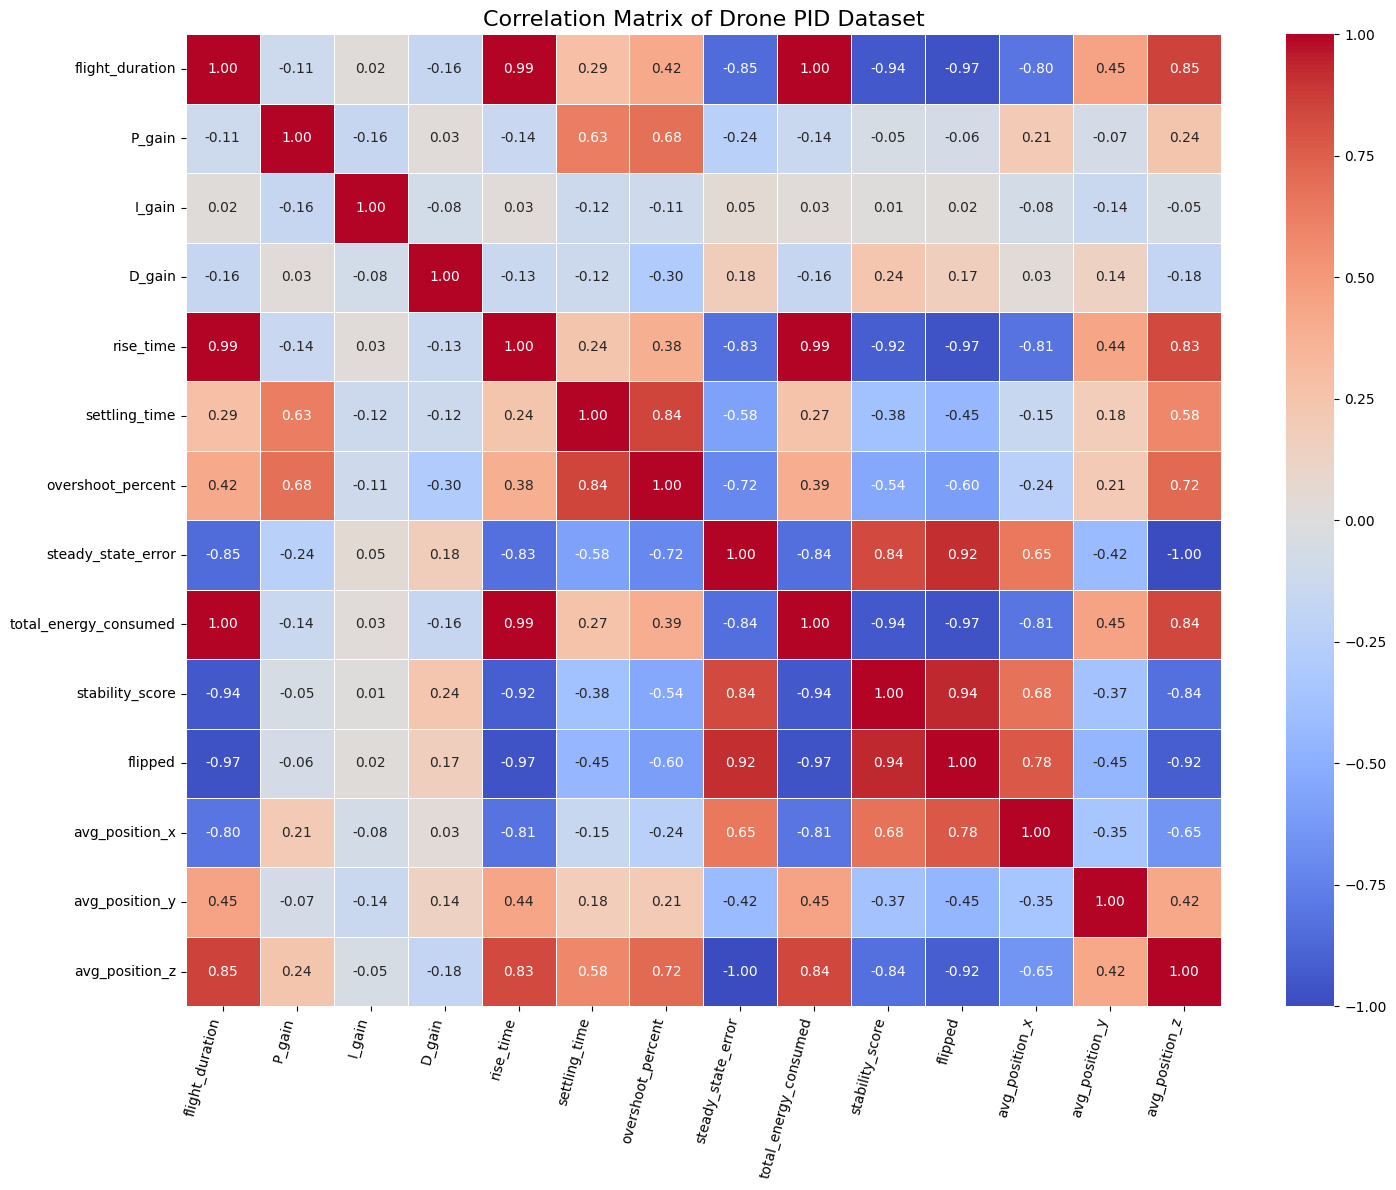

In [ ]:
correlation_matrix = df[plot_cols].corr()

plt.figure(figsize=(15, 12))

sns.heatmap(
    correlation_matrix,
    center=0,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Correlation Matrix of Drone PID Dataset",
    fontsize=16
)

plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# Decision variables - PID parameters

pid_cols = [
    "P_gain",
    "I_gain",
    "D_gain"
]


# Operating conditions

condition_cols = [
    "initial_pitch",
    "initial_roll",
    "initial_y",
    "wind_speed",
    "payload_weight"
]


# Performance metrics

performance_cols = [
    "rise_time",
    "settling_time",
    "overshoot_percent",
    "steady_state_error",
    "total_energy_consumed",
    "stability_score"
]


# Input features for potential surrogate model

feature_cols = pid_cols + condition_cols

X = df[feature_cols].copy()


# Optimization objectives

objective_cols = [
    "settling_time",
    "overshoot_percent",
    "total_energy_consumed"
]

y = df[objective_cols].copy()


print("PID Parameters:")
print(pid_cols)

print("\nOperating Conditions:")
print(condition_cols)

print("\nOptimization Objectives:")
print(objective_cols)

print("\nInput shape:", X.shape)
print("Output shape:", y.shape)

PID Parameters:
['P_gain', 'I_gain', 'D_gain']

Operating Conditions:
['initial_pitch', 'initial_roll', 'initial_y', 'wind_speed', 'payload_weight']

Optimization Objectives:
['settling_time', 'overshoot_percent', 'total_energy_consumed']

Input shape: (100, 8)
Output shape: (100, 3)


In [ ]:
df_normalized = df.copy()

reference_values = {
    "rise_time": 7,
    "settling_time": 6,
    "overshoot_percent": 25,
    "steady_state_error": 1.5,
    "total_energy_consumed": 3500,

}

for column, reference_value in reference_values.items():
    df_normalized[column + "_normalized"] = (
        df_normalized[column] / reference_value
    )

df_normalized["stability_score_nromalized"] = (
    df_normalized["stability_score"]
)

normalized_columns = [
    "rise_time_normalized",
    "settling_time_normalized",
    "overshoot_percent_normalized",
    "steady_state_error_normalized",
    "total_energy_consumed_normalized"

]

display(df_normalized[normalized_columns].head())


display(df_normalized[normalized_columns].describe())

print("Missing values:")
print(df_normalized[normalized_columns].isnull().sum())

print("\nMinimum values:")
print(df_normalized[normalized_columns].min())

print("\nMaximum values:")
print(df_normalized[normalized_columns].max())


,rise_time_normalized,settling_time_normalized,overshoot_percent_normalized,steady_state_error_normalized,total_energy_consumed_normalized
0,0.683429,0.832000,0.6632,0.513200,0.709706
1,0.757714,0.000000,0.0664,0.518400,0.894427
2,0.644571,0.805333,0.4372,0.464267,0.760881
3,0.862857,0.000000,0.0000,0.533267,0.951421
4,0.594286,0.778667,0.3044,0.378933,0.859209


,rise_time_normalized,settling_time_normalized,overshoot_percent_normalized,steady_state_error_normalized,total_energy_consumed_normalized
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,0.524194,0.320387,0.324244,0.543862,0.628351
std,0.281034,0.371923,0.281502,0.161091,0.312759
min,0.000000,0.000000,0.000000,0.378933,0.000000
25%,0.561429,0.000000,0.000000,0.439083,0.683978
50%,0.607429,0.000000,0.340600,0.488900,0.724639
75%,0.700000,0.728333,0.568700,0.530900,0.816931
max,0.862857,0.832000,0.847200,0.941600,0.951619


Missing values:
rise_time_normalized                0
settling_time_normalized            0
overshoot_percent_normalized        0
steady_state_error_normalized       0
total_energy_consumed_normalized    0
dtype: int64

Minimum values:
rise_time_normalized                0.000000
settling_time_normalized            0.000000
overshoot_percent_normalized        0.000000
steady_state_error_normalized       0.378933
total_energy_consumed_normalized    0.000000
dtype: float64

Maximum values:
rise_time_normalized                0.862857
settling_time_normalized            0.832000
overshoot_percent_normalized        0.847200
steady_state_error_normalized       0.941600
total_energy_consumed_normalized    0.951619
dtype: float64


In [ ]:
def fitness_function(row):

    # Kara za wywrócenie drona
    if row["flipped"] == 1:
        return 1000.0

    # Funkcja kosztu
    Q = (
        0.4 * row["rise_time_normalized"]
        + 0.6 * row["settling_time_normalized"]
        + 1.0 * row["overshoot_percent_normalized"]
        + 0.1 * row["steady_state_error_normalized"]
        + 0.1 * row["total_energy_consumed_normalized"]
        + 0.8 * (1 / row["stability_score"] - 1)
    )

    return Q

In [ ]:
df_normalized["Q"] = df_normalized.apply(
    fitness_function,
    axis=1
)

display(
    df_normalized[["P_gain", "I_gain", "D_gain", "Q"]].head(10)
)

,P_gain,I_gain,D_gain,Q
0,2.5389,0.0033,0.7209,2.179526
1,1.4044,0.0072,0.7723,0.994260
2,2.0453,0.0062,0.9588,1.771593
3,1.2015,0.0091,1.0258,0.991891
4,1.4018,0.0017,0.6279,1.482719
5,1.5929,0.0062,1.1658,0.921465
6,2.1712,0.0026,1.1318,1.716825
7,1.6874,0.0057,0.6911,1.261175
8,2.5316,0.0079,1.1748,1.758633
9,2.1818,0.0044,0.9490,1.798429


In [ ]:
# Parametry regulatora PID
pid_parameters = ["P_gain", "I_gain", "D_gain"]

# Wyznaczenie zakresów na podstawie danych
pid_bounds = {
    param: (
        df[param].min(),
        df[param].max()
    )
    for param in pid_parameters
}
for param, bounds in pid_bounds.items():
    print(f"{param}: [{bounds[0]:.4f}, {bounds[1]:.4f}]")

P_gain: [1.2015, 2.7642]
I_gain: [0.0011, 0.0100]
D_gain: [0.5043, 1.1835]


In [ ]:
population_size = 10

valid_data = df_normalized[df_normalized["flipped"] == 0].copy()
best_individuals = valid_data.nsmallest(4,"Q")

remaining_data = valid_data.drop(best_individuals.index)

random_individuals = remaining_data.sample(
    n=population_size - 4,
    random_state=42
)

population = pd.concat(
    [best_individuals, random_individuals],
    ignore_index=True
)

population = population[["episode", "P_gain", "I_gain", "D_gain", "Q"]]

display(population)

,episode,P_gain,I_gain,D_gain,Q
0,6,1.5929,0.0062,1.1658,0.921465
1,36,1.4011,0.0070,1.1703,0.941198
2,69,1.5135,0.0092,1.0307,0.943631
3,74,1.3520,0.0077,1.1665,0.952717
4,5,1.4018,0.0017,0.6279,1.482719
5,86,2.4053,0.0014,1.0294,1.786900
6,12,1.5334,0.0040,0.9141,1.006644
7,1,2.5389,0.0033,0.7209,2.179526
8,53,2.6375,0.0028,0.9642,1.826506
9,84,1.3731,0.0094,0.5914,1.092169


In [ ]:
rng = np.random.default_rng(42)

def tournament_selection(population, tournament_size=3):
  selected_indices = rng.choice(
      len(population), size = tournament_size, replace = False
  )
  tournament_selection = population.iloc[selected_indices]
  winner = tournament_selection.loc[tournament_selection["Q"].idxmin()]
  return winner

In [ ]:
parent1 = tournament_selection(population)

remaining_population = population[
    population["episode"] != parent1["episode"]
]

parent2 = tournament_selection(remaining_population)

def arithmetic_crossover(parent1, parent2):

  p1 = parent1[pid_parameters].to_numpy(dtype=float)
  p2 = parent2[pid_parameters].to_numpy(dtype=float)
  alpha = rng.uniform(0, 1, size=3)

  child1 = alpha * p1 + (1 - alpha) * p2
  child2 = (1 - alpha) * p1 + alpha * p2

  return child1, child2

In [ ]:
child1, child2 = arithmetic_crossover(parent1, parent2)

# Utworzenie tabeli potomków
offspring = pd.DataFrame(
    [child1, child2],
    columns=pid_parameters
)


In [ ]:
def gaussian_mutation(
    individual,
    mutation_probability=0.3,
    mutation_strength=0.1
):

    mutated = np.array(individual, dtype=float, copy=True)

    # Przechodzimy przez każdy parametr PID
    for i, param in enumerate(pid_parameters):

        # Sprawdzenie, czy dany parametr będzie mutowany
        if rng.random() < mutation_probability:

            # Pobranie dozwolonego zakresu
            lower, upper = pid_bounds[param]

            # Obliczenie odchylenia standardowego mutacji
            sigma = mutation_strength * (upper - lower)

            # Wygenerowanie losowej zmiany
            mutation = rng.normal(0, sigma)

            # Modyfikacja parametru
            mutated[i] += mutation

            # Zachowanie wartości w dozwolonym zakresie
            mutated[i] = np.clip(
                mutated[i],
                lower,
                upper
            )

    return mutated

In [ ]:
# Mutacja potomków
mutated_child1 = gaussian_mutation(child1)
mutated_child2 = gaussian_mutation(child2)




,P_gain,I_gain,D_gain
Child 1 - Before,1.588224,0.006391,1.166763
Child 1 - After,1.454919,0.006391,1.166763
Child 2 - Before,1.405776,0.006809,1.169337
Child 2 - After,1.405776,0.006809,1.169337


P_gain: OK
I_gain: OK
D_gain: OK


In [ ]:
def generate_next_generation(
    population,
    elite_size=2,
    generation_number=1
):

    # Kopia obecnej populacji
    current_population = population.reset_index(drop=True).copy()

    population_size = len(current_population)

    # Sprawdzenie, czy wszystkie osobniki zostały ocenione
    if current_population["Q"].isna().any():
        raise ValueError("All individuals must be evaluated before generating a new generation.")

    # 1. ELITYZM
    # Wybieramy najlepszych osobników
    elites = current_population.nsmallest(
        elite_size,
        "Q"
    ).copy()

    elites["status"] = "evaluated"

    elites["candidate_id"] = [
        f"G{generation_number}_E{i+1}"
        for i in range(elite_size)
    ]

    # 2. GENEROWANIE POTOMKÓW
    offspring = []

    number_of_offspring = population_size - elite_size

    while len(offspring) < number_of_offspring:

        # Selekcja pierwszego rodzica
        parent1 = tournament_selection(current_population)

        # Selekcja drugiego, innego rodzica
        remaining = current_population.drop(
            index=parent1.name
        )

        parent2 = tournament_selection(remaining)

        # Krzyżowanie
        child1, child2 = arithmetic_crossover(
            parent1,
            parent2
        )

        # Mutacja
        child1 = gaussian_mutation(child1)
        child2 = gaussian_mutation(child2)

        # Dodawanie potomków
        for child in [child1, child2]:

            if len(offspring) < number_of_offspring:
                offspring.append(child)

    # 3. UTWORZENIE DATAFRAME Z POTOMKAMI
    offspring_df = pd.DataFrame(
        offspring,
        columns=pid_parameters
    )

    # Nowe osobniki nie mają jeszcze wartości Q
    offspring_df["Q"] = np.nan

    offspring_df["status"] = "to_test"

    offspring_df["candidate_id"] = [
        f"G{generation_number}_C{i+1}"
        for i in range(len(offspring_df))
    ]

    # 4. POŁĄCZENIE ELITY I POTOMKÓW
    next_generation = pd.concat(
        [elites, offspring_df],
        ignore_index=True
    )

    return next_generation

In [ ]:
# Generowanie nowej generacji
next_generation = generate_next_generation(
    population,
    elite_size=2,
    generation_number=1
)

# Wyświetlenie wygenerowanej populacji
display(
    next_generation[
        [
            "candidate_id",
            "P_gain",
            "I_gain",
            "D_gain",
            "Q",
            "status"
        ]
    ].round(6)
)

,candidate_id,P_gain,I_gain,D_gain,Q,status
0,G1_E1,1.592900,0.006200,1.165800,0.921465,evaluated
1,G1_E2,1.401100,0.007000,1.170300,0.941198,evaluated
2,G1_C1,1.546501,0.006716,1.183500,NaN,to_test
3,G1_C2,1.511996,0.006484,1.170168,NaN,to_test
4,G1_C3,1.582584,0.007627,1.135145,NaN,to_test
5,G1_C4,1.523816,0.007773,1.061355,NaN,to_test
6,G1_C5,1.391285,0.007005,1.167310,NaN,to_test
7,G1_C6,1.361815,0.007695,1.183500,NaN,to_test
8,G1_C7,1.387291,0.006869,1.166013,NaN,to_test
9,G1_C8,1.341674,0.006988,1.166287,NaN,to_test


# <font color="red"> **Ewaluacja kandydatów w Webots** </font>

Kandydaci ze statusem `to_test` są symulowani tym samym kontrolerem C, który wygenerował `drone_pid_dataset.csv`
(`webots_pid/controllers/drone_pid`, tryb ewaluacji włączany zmiennymi `GA_CANDIDATES` / `GA_RESULTS`).
Wyniki przechodzą przez to samo mapowanie kolumn (`column_rename`), tę samą normalizację (`reference_values`)
i tę samą `fitness_function` co `df`.

**Warunki standardowe:** start z (0, 0, 0.1), wiatr 0, ładunek 0, pełny reset świata przed każdym epizodem
(każdy kandydat ma identyczny scenariusz, wynik nie zależy od kolejności w paczce).

Notebook trzeba uruchamiać **lokalnie** (Webots nie działa w Colab), z plikiem `drone_pid_dataset.csv` obok notebooka.

In [ ]:
# ==== Ewaluacja kandydatów w Webots ====
import os
import sys
import time
import shutil
import subprocess
from datetime import datetime

PROJECT_DIR = Path.cwd().resolve()
WEBOTS_PROJECT_DIR = PROJECT_DIR / "webots_pid"
WEBOTS_WORLD = WEBOTS_PROJECT_DIR / "worlds" / "drone_pid.wbt"
CONTROLLER_DIR = WEBOTS_PROJECT_DIR / "controllers" / "drone_pid"
GA_WORK_DIR = PROJECT_DIR / "ga_runs"
SESSION_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
SESSION_DIR = GA_WORK_DIR / SESSION_ID          # pliki kandydatów / wyników / logów tej sesji
SESSION_DIR.mkdir(parents=True, exist_ok=True)
LOCK_PATH = GA_WORK_DIR / "webots_eval.lock"

WEBOTS_HOME = Path(os.environ.get("WEBOTS_HOME", r"C:\Program Files\Webots"))
if sys.platform == "win32":
    WEBOTS_EXE = WEBOTS_HOME / "msys64" / "mingw64" / "bin" / "webots.exe"
else:
    WEBOTS_EXE = Path(shutil.which("webots") or WEBOTS_HOME / "webots")

TIMEOUT_START_S = 90            # start Webots + wczytanie świata
TIMEOUT_PER_CANDIDATE_S = 30    # jeden epizod to max ~13 s czasu symulacji

metric_cols = [
    "flight_duration", "rise_time", "settling_time", "overshoot_percent",
    "steady_state_error", "total_energy_consumed", "stability_score", "flipped",
    "avg_position_x", "avg_position_y", "avg_position_z",
]


def kill_webots():
    # Zamyka też ręcznie otwarte okna Webots
    if sys.platform == "win32":
        for exe in ["webots.exe", "webots-bin.exe", "drone_pid.exe"]:
            subprocess.run(["taskkill", "/F", "/T", "/IM", exe], capture_output=True)
    else:
        subprocess.run(["pkill", "-f", "webots"], capture_output=True)


def process_alive(pid):
    if sys.platform == "win32":
        out = subprocess.run(["tasklist", "/FI", f"PID eq {pid}", "/NH"], capture_output=True, text=True).stdout
        return str(pid) in out
    try:
        os.kill(pid, 0)
    except OSError:
        return False
    return True


def acquire_lock():
    # Jedna ewaluacja naraz: kill_webots() zabiłby Webots innego, równolegle działającego notebooka
    if LOCK_PATH.exists():
        try:
            other_pid = int(LOCK_PATH.read_text().strip())
        except ValueError:
            other_pid = None
        if other_pid and other_pid != os.getpid() and process_alive(other_pid):
            raise RuntimeError(
                f"Inna ewaluacja Webots już działa (PID {other_pid}, {LOCK_PATH}). Poczekaj na jej koniec."
            )
    LOCK_PATH.write_text(str(os.getpid()))


def build_controller():
    # Kompilacja kontrolera, jeśli exe nie istnieje lub jest starszy niż źródło
    exe = CONTROLLER_DIR / ("drone_pid.exe" if sys.platform == "win32" else "drone_pid")
    src = CONTROLLER_DIR / "drone_pid.c"
    if exe.exists() and exe.stat().st_mtime >= src.stat().st_mtime:
        return
    env = os.environ.copy()
    env["WEBOTS_HOME"] = str(WEBOTS_HOME)
    if sys.platform == "win32":
        env["PATH"] = os.pathsep.join([
            str(WEBOTS_HOME / "msys64" / "mingw64" / "bin"),
            str(WEBOTS_HOME / "msys64" / "usr" / "bin"),
            env["PATH"],
        ])
    subprocess.run(["make"], cwd=CONTROLLER_DIR, env=env, check=True)


def normalize_metrics(frame):
    # Ta sama normalizacja co dla df
    frame = frame.copy()
    for column, reference_value in reference_values.items():
        frame[column + "_normalized"] = frame[column] / reference_value
    frame["stability_score_nromalized"] = frame["stability_score"]
    return frame


def evaluate_candidates(df_to_test, world=WEBOTS_WORLD, extra_env=None, tag="eval"):
    """Symuluje kandydatów (candidate_id, P_gain, I_gain, D_gain) w jednej instancji Webots i zwraca metryki + Q."""
    candidates = df_to_test[["candidate_id"] + pid_parameters].reset_index(drop=True).copy()
    candidates["candidate_id"] = candidates["candidate_id"].astype(str)

    candidates_path = (SESSION_DIR / f"{tag}_candidates.csv").resolve()
    results_path = (SESSION_DIR / f"{tag}_results.csv").resolve()
    log_path = (SESSION_DIR / f"{tag}_webots.log").resolve()
    results_path.unlink(missing_ok=True)
    candidates.to_csv(candidates_path, index=False, float_format="%.10g")

    env = os.environ.copy()
    env.update({
        "WEBOTS_HOME": str(WEBOTS_HOME),
        "GA_CANDIDATES": str(candidates_path),
        "GA_RESULTS": str(results_path),
    })
    if extra_env:
        env.update(extra_env)

    cmd = [str(WEBOTS_EXE), "--batch", "--mode=fast", "--no-rendering", "--minimize",
           "--stdout", "--stderr", str(Path(world).resolve())]
    timeout = TIMEOUT_START_S + TIMEOUT_PER_CANDIDATE_S * len(candidates)

    acquire_lock()
    try:
        build_controller()
        kill_webots()
        start = time.time()
        # Wyjście Webots przez pipe (przekierowanie do pliku na Windows daje pusty log)
        proc = subprocess.Popen(cmd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        try:
            output, _ = proc.communicate(timeout=timeout)
            run_status = f"exit code {proc.returncode}"
        except subprocess.TimeoutExpired:
            kill_webots()
            output, _ = proc.communicate()
            run_status = f"TIMEOUT po {timeout} s"
        kill_webots()
        elapsed = time.time() - start
    finally:
        LOCK_PATH.unlink(missing_ok=True)

    log_text = (output or b"").decode("utf-8", errors="replace")
    log_path.write_text(log_text, encoding="utf-8")

    if results_path.exists() and results_path.stat().st_size > 0:
        sim = pd.read_csv(results_path)
    else:
        sim = pd.DataFrame(columns=["candidate_id"])

    # To samo mapowanie kolumn co przy wczytywaniu df
    sim = sim.rename(columns=column_rename)
    for col in metric_cols:
        if col not in sim.columns:
            sim[col] = np.nan
    sim["candidate_id"] = sim["candidate_id"].astype(str)
    sim = sim.drop_duplicates("candidate_id", keep="last")

    # P/I/D z kandydatów (pełna precyzja), metryki z symulacji
    results = candidates.merge(sim[["candidate_id"] + metric_cols], on="candidate_id", how="left")
    results["sim_ok"] = results["flipped"].notna()

    # Brak wyniku (crash / timeout) => jak wywrotka => Q = 1000
    results.loc[~results["sim_ok"], "flipped"] = 1
    results["flipped"] = results["flipped"].astype(int)

    results = normalize_metrics(results)
    results["Q"] = results.apply(fitness_function, axis=1)

    n_missing = int((~results["sim_ok"]).sum())
    print(f"[{tag}] Webots: {len(candidates)} kandydatów, {elapsed:.1f} s, {run_status}, brak wyniku: {n_missing}")
    if n_missing:
        print("Kandydaci bez wyniku (Q = 1000):", results.loc[~results["sim_ok"], "candidate_id"].tolist())
        print(f"--- końcówka logu Webots ({log_path}) ---")
        print("\n".join(log_text.splitlines()[-30:]))

    return results

In [ ]:
# ==== Test zgodności z df ====
# df powstał przy starcie drona w ok. (-7.58, 3.35, 0.1) (miejsce, w którym dron był przy uruchomieniu
# kontrolera; wyznaczone z avg_position_x/y w df) i z epizodami puszczanymi jeden po drugim
# (bez pełnego resetu świata). Żeby porównać 1:1, odtwarzamy te warunki w tymczasowej kopii świata.
DF_START_TRANSLATION = "-7.5772 3.3482 0.1"
test_episodes = [6, 36, 69]

# Epizody 1-5 przed 6 oraz bezpośredni poprzednicy -> stan symulacji jak w oryginalnym przebiegu
known_episodes = set(df["episode"])
sequence = list(range(1, 6))
for ep in test_episodes:
    sequence += [ep - 1, ep]
sequence = [ep for ep in dict.fromkeys(sequence) if ep in known_episodes]

compat_candidates = df.set_index("episode").loc[sequence, pid_parameters].reset_index()
compat_candidates["candidate_id"] = "ep" + compat_candidates["episode"].astype(str)

df_world = WEBOTS_WORLD.with_name("_df_start.wbt")
world_text = WEBOTS_WORLD.read_text(encoding="utf-8")
assert world_text.count("translation 0 0 0.1") == 1
df_world.write_text(world_text.replace("translation 0 0 0.1", f"translation {DF_START_TRANSLATION}"), encoding="utf-8")
try:
    compat = evaluate_candidates(compat_candidates, world=df_world, extra_env={"GA_FULL_RESET": "0"}, tag="compat")
finally:
    for f in WEBOTS_WORLD.parent.glob("*_df_start*"):
        f.unlink()

compare_cols = ["rise_time", "settling_time", "overshoot_percent", "steady_state_error",
                "total_energy_consumed", "stability_score", "flipped", "Q"]
df_ref = df_normalized.set_index("episode")
sim_ref = compat.set_index("candidate_id")

comparison = pd.DataFrame([
    {
        "episode": ep,
        "metric": col,
        "df": df_ref.loc[ep, col],
        "webots": sim_ref.loc[f"ep{ep}", col],
    }
    for ep in test_episodes
    for col in compare_cols
])
comparison["diff"] = comparison["webots"] - comparison["df"]
comparison["diff_%"] = 100 * comparison["diff"] / comparison["df"].abs().replace(0, np.nan)

display(comparison.round(4))

In [ ]:
# ==== Populacja startowa w warunkach standardowych ====
# Q z df pochodzi z innego punktu startu (patrz test zgodności), więc te same osobniki populacji startowej
# oceniamy ponownie w Webots - elity i potomkowie są wtedy porównywani w identycznym scenariuszu.
REEVALUATE_INITIAL_POPULATION = True

population_ga = population.copy()
population_ga["candidate_id"] = "G0_ep" + population_ga["episode"].astype(int).astype(str)
population_ga["status"] = "evaluated"

g0_results = None
if REEVALUATE_INITIAL_POPULATION:
    g0_results = evaluate_candidates(population_ga, tag="G0")
    q_webots = population_ga["candidate_id"].map(g0_results.set_index("candidate_id")["Q"])
    display(
        population_ga[["candidate_id", "P_gain", "I_gain", "D_gain"]]
        .assign(Q_df=population_ga["Q"], Q_webots=q_webots)
        .round(6)
    )
    population_ga["Q"] = q_webots

In [ ]:
# ==== Pętla pokoleń GA z ewaluacją w Webots ====
N_GENERATIONS = 2
ELITE_SIZE = 2

GA_LOG_PATH = GA_WORK_DIR / "ga_log.csv"
run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

# (P, I, D) -> metryki; elity nie są symulowane ponownie, metryki do logu biorą stąd
sim_cache = {}


def remember(results):
    for _, row in results.iterrows():
        sim_cache[tuple(row[pid_parameters])] = row


def log_generation(pop, generation):
    rows = []
    for _, ind in pop.iterrows():
        sim_row = sim_cache.get(tuple(ind[pid_parameters]))
        row = {
            "run_id": run_id,
            "generation": generation,
            "candidate_id": ind["candidate_id"],
            "is_elite": "_E" in str(ind["candidate_id"]),
        }
        row.update({param: ind[param] for param in pid_parameters})
        row.update({col: (sim_row[col] if sim_row is not None else np.nan) for col in metric_cols})
        row["Q"] = ind["Q"]
        rows.append(row)
    pd.DataFrame(rows).to_csv(GA_LOG_PATH, mode="a", header=not GA_LOG_PATH.exists(), index=False)


if g0_results is not None:
    remember(g0_results)
log_generation(population_ga, 0)

ga_history = [{
    "generation": 0,
    "best_Q": population_ga["Q"].min(),
    "mean_Q": population_ga["Q"].mean(),
    "n_Q1000": int((population_ga["Q"] >= 1000).sum()),
    "time_s": np.nan,
}]

for generation in range(1, N_GENERATIONS + 1):
    start = time.time()

    next_generation = generate_next_generation(
        population_ga,
        elite_size=ELITE_SIZE,
        generation_number=generation
    )

    to_test = next_generation["status"] == "to_test"
    results = evaluate_candidates(next_generation.loc[to_test], tag=f"G{generation}")
    remember(results)

    q_by_id = results.set_index("candidate_id")["Q"]
    next_generation.loc[to_test, "Q"] = next_generation.loc[to_test, "candidate_id"].map(q_by_id)
    next_generation.loc[to_test, "status"] = "evaluated"

    population_ga = next_generation
    elapsed = time.time() - start
    log_generation(population_ga, generation)

    ga_history.append({
        "generation": generation,
        "best_Q": population_ga["Q"].min(),
        "mean_Q": population_ga["Q"].mean(),
        "n_Q1000": int((population_ga["Q"] >= 1000).sum()),
        "time_s": elapsed,
    })

    print(f"Pokolenie {generation}: {elapsed:.1f} s, najlepsze Q = {population_ga['Q'].min():.6f}, "
          f"Q = 1000: {ga_history[-1]['n_Q1000']} (w tym brak wyniku z Webots: {int((~results['sim_ok']).sum())})")
    display(population_ga[["candidate_id", "P_gain", "I_gain", "D_gain", "Q", "status"]].round(6))

ga_history = pd.DataFrame(ga_history)
display(ga_history.round(6))
print("Log:", GA_LOG_PATH)

In [ ]:
# ==== Najlepsze Q w funkcji pokolenia ====
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(ga_history["generation"], ga_history["best_Q"],
        color="#2a78d6", linewidth=2, marker="o", markersize=8)

last = ga_history.iloc[-1]
ax.annotate(f"{last['best_Q']:.4f}", (last["generation"], last["best_Q"]),
            textcoords="offset points", xytext=(8, 8), color="#52514e")

ax.set_title("Najlepsze Q w pokoleniu (mniej = lepiej)", loc="left")
ax.set_xlabel("Pokolenie")
ax.set_ylabel("Q")
ax.set_xticks(ga_history["generation"])
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig(GA_WORK_DIR / f"best_q_{run_id}.png", dpi=150)
plt.show()